In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/bagassenop/cardekho/main/CAR%20DETAILS%20FROM%20CAR%20DEKHO.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB

Statistical Summary:


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000



Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate Records: 763


In [4]:
df = df.drop_duplicates()
df = df.dropna()

# Extract car brand
df['brand'] = df['name'].str.split().str[0]

# Remove invalid records
df = df[
    (df['selling_price'] > 0) &
    (df['km_driven'] >= 0) &
    (df['year'] >= 1900)
].copy()

# Select relevant features
df = df[
    ['year', 'km_driven', 'fuel',
     'seller_type', 'transmission', 'owner',
     'brand', 'selling_price']
]

print("Preprocessing completed!")
print("Final Dataset Shape:", df.shape)

df.head()

Preprocessing completed!
Final Dataset Shape: (3577, 8)


,year,km_driven,fuel,seller_type,transmission,owner,brand,selling_price
0,2007,70000,Petrol,Individual,Manual,First Owner,Maruti,60000
1,2007,50000,Petrol,Individual,Manual,First Owner,Maruti,135000
2,2012,100000,Diesel,Individual,Manual,First Owner,Hyundai,600000
3,2017,46000,Petrol,Individual,Manual,First Owner,Datsun,250000
4,2014,141000,Diesel,Individual,Manual,Second Owner,Honda,450000


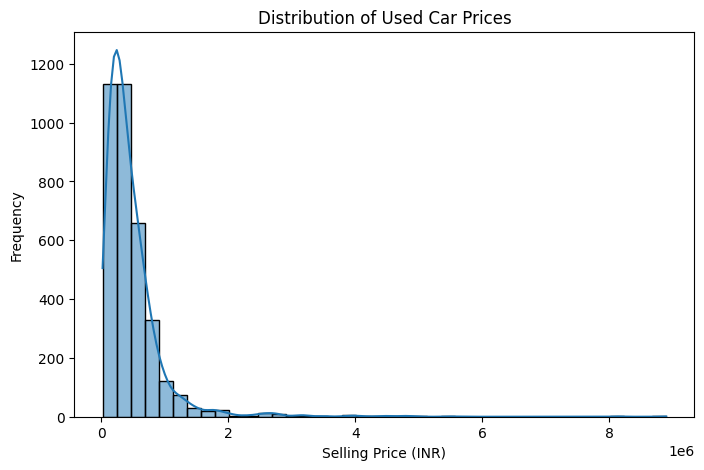

In [5]:
plt.figure(figsize=(8,5))
sns.histplot(df['selling_price'], bins=40, kde=True)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Frequency")
plt.show()

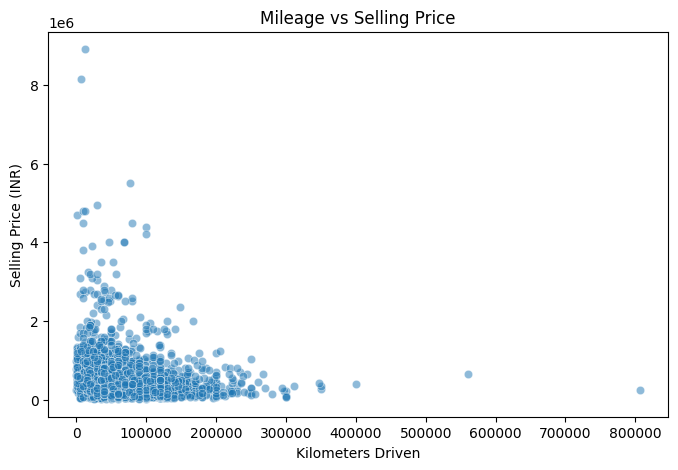

In [6]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='km_driven',
    y='selling_price',
    alpha=0.5
)

plt.title("Mileage vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (INR)")
plt.show()

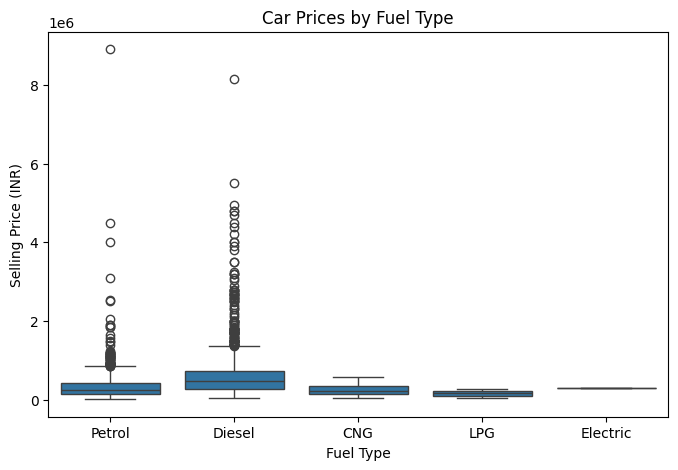

In [7]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='fuel',
    y='selling_price'
)

plt.title("Car Prices by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (INR)")
plt.show()

In [8]:
X = df.drop('selling_price', axis=1)
y = df['selling_price']

numerical_features = ['year', 'km_driven']

categorical_features = [
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'brand'
]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2861
Testing samples: 716


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Feature preprocessing configured!")

Feature preprocessing configured!


In [10]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=250,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    print(f"\n{name} trained successfully!")


Linear Regression trained successfully!

Decision Tree trained successfully!

Random Forest trained successfully!


In [11]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='R2 Score',
        ascending=False
    ).round(3)
)

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,156135.264,1.289117e+11,359042.816,0.600
0,Linear Regression,179642.888,1.480115e+11,384722.685,0.541
1,Decision Tree,184795.219,2.153746e+11,464084.702,0.331


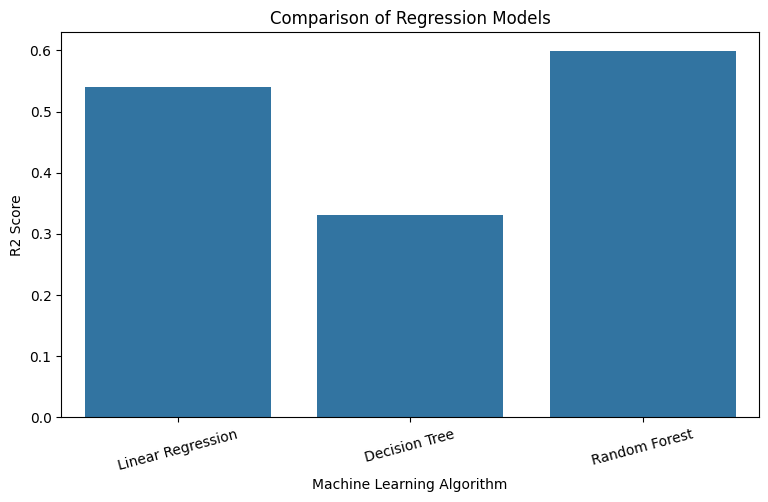

In [12]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Comparison of Regression Models")
plt.ylabel("R2 Score")
plt.xlabel("Machine Learning Algorithm")
plt.xticks(rotation=15)
plt.show()

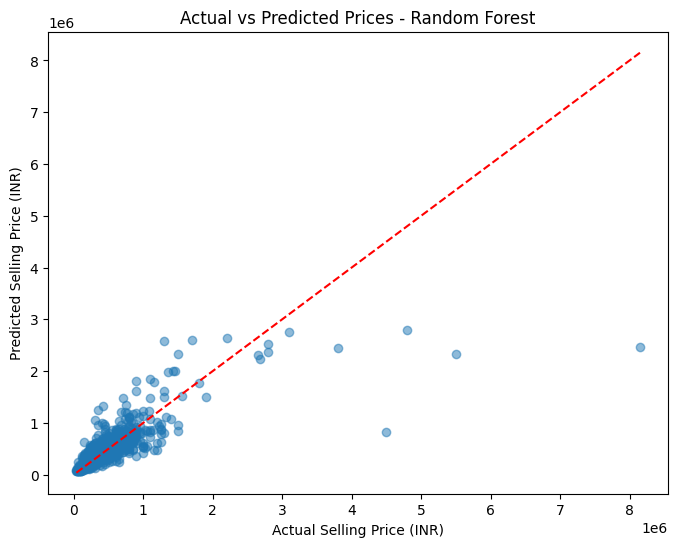

Best Performing Model: Random Forest


In [13]:
best_model_name = results_df.sort_values(
    by='R2 Score',
    ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(8,6))

plt.scatter(y_test, predictions, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title(f"Actual vs Predicted Prices - {best_model_name}")
plt.xlabel("Actual Selling Price (INR)")
plt.ylabel("Predicted Selling Price (INR)")
plt.show()

print("Best Performing Model:", best_model_name)

In [14]:
sample_car = pd.DataFrame([{
    'year': 2018,
    'km_driven': 45000,
    'fuel': 'Petrol',
    'seller_type': 'Individual',
    'transmission': 'Manual',
    'owner': 'First Owner',
    'brand': 'Maruti'
}])

predicted_price = best_model.predict(sample_car)[0]

print("Used Car Price Prediction")
print("-------------------------")
print("Car Brand: Maruti")
print("Manufacturing Year: 2018")
print("Kilometers Driven: 45000")
print(f"Estimated Selling Price: ₹{predicted_price:,.2f}")

Used Car Price Prediction
-------------------------
Car Brand: Maruti
Manufacturing Year: 2018
Kilometers Driven: 45000
Estimated Selling Price: ₹513,014.81


In [16]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': predictions
})

comparison['Absolute Error'] = abs(
    comparison['Actual Price'] - comparison['Predicted Price']
)

# Closest prediction
correct_example = comparison.loc[
    comparison['Absolute Error'].idxmin()
]

# Largest prediction error
incorrect_example = comparison.loc[
    comparison['Absolute Error'].idxmax()
]

print("CORRECT / CLOSE PREDICTION")
print(correct_example)

print("\nINCORRECT / HIGH-ERROR PREDICTION")
print(incorrect_example)

CORRECT / CLOSE PREDICTION
Actual Price       500000.000000
Predicted Price    500610.627484
Absolute Error        610.627484
Name: 398, dtype: float64

INCORRECT / HIGH-ERROR PREDICTION
Actual Price       8.150000e+06
Predicted Price    2.457880e+06
Absolute Error     5.692120e+06
Name: 187, dtype: float64


Results saved successfully!


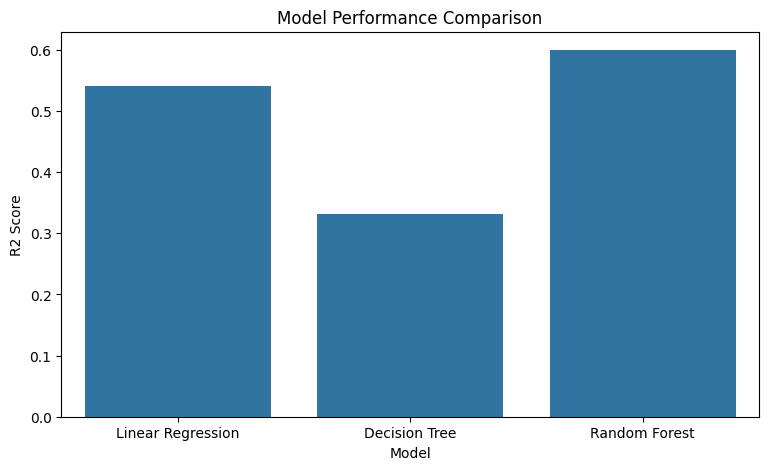

In [17]:
import os

os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Model Performance Comparison")
plt.savefig(
    "results/model_comparison.png",
    bbox_inches='tight'
)

print("Results saved successfully!")